# Single transect original resolution data organization for creating interoperable machine learning datasets for echogram classification tasks

```{admonition} This notebook accompanies the following paper:
:class: tip
**An open-source, scalable workflow for organizing echosounder data for machine learning applications**\
Authors: Caesar Tuguinay, Wu-Jung Lee, Valentina Staneva, Elizabeth M. Phillips, Rebecca E. Thomas, Alicia Billings, and Julia Clemons\
The manuscript has been submitted for consideration for publication.\
The preprint is available on arXiv: https://arxiv.org/abs/2608.09821
```

## Introduction

This notebook is a modification of [`single_transect_data_organization.ipynb`](single_transect_data_organization.ipynb) that skips the regridding steps and preserves the original time and depth resolution in the final datasets.

### Description

This notebook uses a single transect of the EK60 echosounder data collected during the [2019 Joint U.S.-Canada Integrated Ecosystem and Pacific Hake Acoustic Trawl Survey (the "Hake survey")](https://www.fisheries.noaa.gov/west-coast/science-data/joint-us-canada-integrated-ecosystem-and-pacific-hake-acoustic-trawl-survey) to illustrate a processing pipeline for creating interoperable machine learning datasets for echogram classification tasks. The workflow includes steps to perform data conversion, calibration, and masking, using functions from [`Echopype`](https://echopype.readthedocs.io), [`Echoregions`](https://echoregions.readthedocs.io), and core scientific Python software packages, particularly `Xarray` and `Dask`. This workflow utilizes hake annotations which were manually produced by the NOAA Fisheries Northwest Fisheries Science Center (NWFSC) [Fisheries Engineering and Acoustic Technologies Team (FEAT)](https://www.fisheries.noaa.gov/west-coast/sustainable-fisheries/fisheries-engineering-and-acoustic-technologies-team).

### Outline

1) [Transect data organization](##Transect-data-organization)
2) [Clean fish mask creation](##Clean-fish-mask-creation)

### Running the notebook

This notebook can be run with a conda environment created using the [conda environment file](../conda/environment-ep-main.yml). The notebook creates a directory, if not already present: `./exports/single_transect_data_organization`. All Zarr files will be exported there.

### Note
We encourage importing Echopype as `ep` for consistency.

In [2]:
# Import packages

import warnings
from pathlib import Path
import re
from datetime import datetime

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import fsspec
import pandas as pd
from dask.distributed import Client
from zarr.errors import ZarrUserWarning

import echopype as ep
import echoregions as er

# Silence the expected consolidated metadata warnings from Zarr v3
warnings.filterwarnings("ignore", category=ZarrUserWarning)

### Setup Dask and file directories

As most personal devices have 4 CPU cores and 16 GB of RAM, we demonstrate running the workflow using a local-cluster containing 2 low-resource Dask workers:
- Each worker is a separate process with 2 threads (CPU cores) for concurrent execution of tasks
- Each worker is limited to 4 GB of RAM, for a total cluster memory of 16 GB

In [2]:
client = Client(n_workers=2, threads_per_worker=2, memory_limit="8GB")

In [3]:
print("Dask dashboard URL:", client.dashboard_link)

Dask dashboard URL: http://127.0.0.1:8787/status


In [4]:
# Create directories
base_path = Path("./exports/single_transect_original_resolution_data_organization")
base_path.mkdir(exist_ok=True, parents=True)
echodata_zarr_directory_path = base_path / "echodata_zarr"
echodata_zarr_directory_path.mkdir(exist_ok=True)
Sv_zarr_directory_path = base_path / "Sv_zarr"
Sv_zarr_directory_path.mkdir(exist_ok=True)
combined_zarr_directory_path = base_path / "combined_zarr"
combined_zarr_directory_path.mkdir(exist_ok=True)

## Transect data organization

Parse the `.evr` file using Echoregions' `read_evr` function. The parsing is based off of the `.evr` data description shown on Echoview's website: [Region Attributes](https://support.echoview.com/WebHelp/Reference/File_Formats/Export_File_Formats/2D_Region_definition_file_format.htm).

In [17]:
# Read region object
regions_object = er.read_evr("example_data/single_transect_data_organization/transect_53_year_2019_regions.evr")
regions_object.data[["region_id", "region_name", "region_class"]]

,region_id,region_name,region_class
0,1,ST53,Log
1,2,BT53,Log
2,3,RT53,Log
3,4,ET53,Log
4,5,H47U-Region 43,Hake
5,6,H47U-Region 44,Hake
6,7,H46U-Region 45,Hake
7,8,H51U-Region 46,Hake


ST stands for Start Transect, ET for End Transect, BT for Break Transect, and RT for Resume Transect. Any data collected between the intervals ST–ET, RT–ET, ST–BT, or RT–BT is considered within-transect (WT), while all other data is outside-transect (OT). Our goal is to capture the times associated with ST and ET events to subset the backscatter data, ensuring we include all data collected within the transect boundaries. Throughout this notebook, we will refer to hake as fish to emphasize that this workflow is not specific to the Hake Survey.

In [7]:
# Find time range
start_time = regions_object.select_region(region_id=1)["time"][0].min()
end_time = regions_object.select_region(region_id=4)["time"][3].max()
start_time = pd.to_datetime(start_time).to_pydatetime()
end_time = pd.to_datetime(end_time).to_pydatetime()
print("Start time:", str(start_time))
print("End time:", str(end_time))

Start time: 2019-07-23 19:17:52.423500
End time: 2019-07-24 02:26:06.458000


This code sets up access to an S3 bucket containing raw EK60 acoustic files, extracts timestamps from the filenames, and selects all files within the ST-ET time window. It also includes the first file immediately before the start time and the first file immediately after the end time to ensure full coverage of the transect range.

In [8]:
# Setup the filesystem that points to the .raw directory
fs = fsspec.filesystem("s3", anon=True)
bucket = "noaa-wcsd-pds"
rawdirpath = "data/raw/Bell_M._Shimada/SH1906/EK60"

# Regex and helper function for filenames such as SH-19-06-D20190617-T123400.raw
pattern = re.compile(r"D(\d{8})-T(\d{6})")
def extract_datetime_from_path(path):
    """
    Extract datetime from EK60 filename, e.g.:
    SH-19-06-D20190617-T121905.raw
    """
    match = pattern.search(path)
    if not match:
        return None
    date_str, time_str = match.groups()
    return datetime.strptime(date_str + time_str, "%Y%m%d%H%M%S")

# Filter files within the time window
s3rawfiles = fs.glob(f"{bucket}/{rawdirpath}/*.raw")
select_files = []
for s3path in s3rawfiles:
    ts = extract_datetime_from_path(s3path)
    if ts is not None and start_time <= ts <= end_time:
        select_files.append(s3path)

# Sort all files with timestamps and find first file before
# ST time and first file after ET time and place in select_files
all_files_with_time = []
for s3path in s3rawfiles:
    ts = extract_datetime_from_path(s3path)
    if ts is not None:
        all_files_with_time.append((ts, s3path))
all_files_with_time.sort(key=lambda x: x[0])
all_times = [t for t, _ in all_files_with_time]
all_paths = [p for _, p in all_files_with_time]
selected_times = [extract_datetime_from_path(f) for f in select_files]
selected_times_sorted = sorted(selected_times)
first_time = selected_times_sorted[0]
last_time = selected_times_sorted[-1]
first_idx = all_times.index(first_time)
last_idx = all_times.index(last_time)
file_before = all_paths[first_idx - 1] if first_idx > 0 else None
file_after = all_paths[last_idx + 1] if last_idx < len(all_paths) - 1 else None
select_files.insert(0, file_before)
select_files.append(file_after)

print(f"There are {len(select_files)} target raw files available")

There are 40 target raw files available


In [9]:
# Check sizes for selected files
file_sizes = []
for f in select_files:
    if f is not None:
        size_bytes = fs.size(f)
        file_sizes.append((f, size_bytes))

# Print results
for f, size in file_sizes:
    print(f"{f}: {size / 1e6:.2f} MB")  # size in MB

# Check total size of all selected files
total_size = sum(size for _, size in file_sizes)
print(f"Total size of selected files: {total_size / 1e6:.2f} MB")

noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T190606.raw: 26.27 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T192100.raw: 26.24 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T193442.raw: 26.27 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T194623.raw: 26.27 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T195757.raw: 26.25 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T200848.raw: 26.27 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T202323.raw: 26.28 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T203819.raw: 26.29 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T205342.raw: 26.23 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T211035.raw: 26.28 MB
noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH1906/EK60/SH-19-06-D20190723-T212629.ra

### Convert EK60 `.raw` files to EchoData objects, calibrate, and save to Zarr

The code block below follows a typical Echopype workflow. Each EK60 `.raw` file is converted into an EchoData object, calibrated to compute volume backscattering strength (Sv; dB re 1 m^-1), and variables such as depth and geographic location (latitude and longitude) are appended to the Sv data. The resulting calibrated Sv dataset is then written directly to a Zarr store on disk.

More information on lazy loading can be found [here](https://en.wikipedia.org/wiki/Lazy_loading).

The execution time of the following code largely depends on the connection to the S3 bucket:

In [10]:
%%time

def parse_calibrate_and_save(
    raw_file,
    sonar_model,
    use_swap,
    echodata_output_dir,
    Sv_output_dir,
    storage_options,
):
    # Silence warnings inside each task as logger behavior and warning filters cannot be
    # inherited from the main process.

    # Silence the warning expected for calibrating EK60 files generated from
    # General Purpose Transducer (GPT) models.
    warnings.filterwarnings(
        "ignore",
        message="Could not compute tau_effective from transmit signal in power encoding mode.*",
        category=RuntimeWarning,    
    )

    # Silence the 'not implemented' consolidated metadata warnings from Zarr v3. This
    # warning is expected when saving Zarr v3 files with consolidated metadata, and
    # does not impact the functionality of the code, so we can safely ignore it for now.
    warnings.filterwarnings("ignore", category=ZarrUserWarning)

    # Ignore future warnings about chunk formatting. An issue for this has been
    # opened and will be addressed in a future release of echopype. This currently
    # does not impact the functionality of the code, so we can also safely ignore it for
    # now.
    warnings.filterwarnings(
        "ignore",
        category=FutureWarning,
        message=".*Supplying chunks as dimension-order tuples",
    )

    # Parse .raw file into echodata object
    ed = ep.open_raw(
        raw_file=f"s3://{raw_file}",
        sonar_model=sonar_model,
        use_swap=use_swap,
        storage_options=storage_options,
    )

    # Save echodata
    filename = Path(raw_file).stem
    echodata_save_path = Path(echodata_output_dir) / f"{filename}_echodata.zarr"
    ed.to_zarr(
        echodata_save_path,
        overwrite=True,
        compute=True,
    )

    # Re-open the saved echodata to read it back lazily
    ed = ep.open_converted(converted_raw_path=echodata_save_path)

    # Calibrate
    ds_Sv = ep.calibrate.compute_Sv(ed)

    # Add auxiliary variables
    ds_Sv = ep.consolidate.add_location(ds_Sv, ed)
    ds_Sv = ep.consolidate.add_depth(
        ds_Sv,
        depth_offset=9.15,
    )

    # Create a unique output path for this file
    Sv_save_path = Path(Sv_output_dir) / f"{filename}_Sv.zarr"

    # Save calibrated dataset
    ds_Sv.to_zarr(
        Sv_save_path,
        mode="w",
        compute=True,
    )

# Run the `parse_calibrate_and_save` task for each `.raw` file in parallel using Dask
tasks = []
for raw_file_url in select_files:
    task = client.submit(
        parse_calibrate_and_save,
        raw_file=raw_file_url,
        sonar_model="EK60",
        use_swap=True,
        echodata_output_dir=echodata_zarr_directory_path,
        Sv_output_dir=Sv_zarr_directory_path,
        storage_options={"anon": True},
    )
    tasks.append(task)
_ = client.gather(tasks)

parsing file SH-19-06-D20190723-T193442.raw, time of first ping: 2019-Jul-23 19:34:42
saving exports/single_transect_original_resolution_data_organization/echodata_zarr/SH-19-06-D20190723-T193442_echodata.zarr
parsing file SH-19-06-D20190723-T190606.raw, time of first ping: 2019-Jul-23 19:06:06
saving exports/single_transect_original_resolution_data_organization/echodata_zarr/SH-19-06-D20190723-T190606_echodata.zarr
parsing file SH-19-06-D20190723-T192100.raw, time of first ping: 2019-Jul-23 19:21:00
saving exports/single_transect_original_resolution_data_organization/echodata_zarr/SH-19-06-D20190723-T192100_echodata.zarr
parsing file SH-19-06-D20190723-T194623.raw, time of first ping: 2019-Jul-23 19:46:23
parsing file SH-19-06-D20190723-T202323.raw, time of first ping: 2019-Jul-23 20:23:23
saving exports/single_transect_original_resolution_data_organization/echodata_zarr/SH-19-06-D20190723-T194623_echodata.zarr
saving exports/single_transect_original_resolution_data_organization/echod

### Combine calibrated data

The previous step produced one calibrated Zarr store for each raw EK60 `.raw` file. Here, these individual Zarr stores are lazily opened and combined into a single dataset using `xarray.open_mfdataset()`.

In [21]:
# Lazy-load all calibrated Sv datasets and then combine them into a single dataset
ds_combined_Sv = xr.open_mfdataset(
    Sv_zarr_directory_path.glob("*_Sv.zarr"),
    engine="zarr",
    data_vars="minimal",
    coords="minimal",
    # Set `compat="override"` to avoid conflicting values for
    # variable 'source_filenames'
    compat="override",
)

In [18]:
ds_combined_Sv["depth"]

<xarray.DataArray 'depth' (channel: 5, ping_time: 13047, range_sample: 3957)> Size: 2GB
dask.array<concatenate, shape=(5, 13047, 3957), dtype=float64, chunksize=(1, 82, 990), chunktype=numpy.ndarray>
Coordinates:
  * channel       (channel) StringDType() 80B 'GPT  18 kHz 009072058c8d 1-1 E...
  * ping_time     (ping_time) datetime64[ns] 104kB 2019-07-23T19:06:06.472269...
  * range_sample  (range_sample) int64 32kB 0 1 2 3 4 ... 3953 3954 3955 3956
Attributes:
    long_name:  Range distance
    units:      m
    history:    2026-10-28 21:25:01.482448+00:00. `depth` calculated using: S...

Depth is a variable with dimensions frequency/channel, ping_time, and range_sample. For this dataset, depth is consistent across channels and ping times, so we can select a single 1D depth array corresponding to the 18 kHz channel at the first ping time to replace `range_sample`. This way, measurements can be indexed by physical depth rather than sample index.

If depth is not uniform across channels and ping time, please refer to the regridding shown in [`single_transect_data_organization.ipynb`](single_transect_data_organization.ipynb).

In [22]:
depth_1d = ds_combined_Sv["depth"].sel(channel="GPT  18 kHz 009072058c8d 1-1 ES18-11").isel(ping_time=0)
ds_combined_Sv["depth"] = depth_1d
ds_combined_Sv = ds_combined_Sv.swap_dims({"range_sample": "depth"})

The combined dataset is then saved as a new Zarr store for efficient downstream analysis and re-opened lazily:

In [23]:
# Save the combined dataset
combined_path = combined_zarr_directory_path / "combined_ds_Sv.zarr"
ds_combined_Sv.to_zarr(
    combined_path,
    mode="w",
    compute=True,
    # Align chunks to avoid overlapping chunking issues. Easier than manually
    # specifying chunk sizes and removing existing chunk metadata.
    align_chunks=True,
)

# Lazy-load the combined dataset
ds_combined_Sv = xr.open_dataset(
    combined_path,
    engine="zarr",
    chunks={},
)

The user can optionally identify and remove noise from the Sv data using a variety of functions from the `echopype.clean` subpackage. In particular, the `transient_noise.ipynb` notebook details how to identify and remove transient noise from the Sv data. The Hake Survey echo data contains very little noise so we do not demonstrate this functionality here.

### Transect-based splitting

As previously shown, the regions object contains transect information. We can use this to create a transect mask for the calibrated backscatter data, where a value of `1` indicates WT data and a value of `0` indicates OT data.

In [24]:
transect_mask = regions_object.transect_mask(
    ds_combined_Sv["Sv"],
)

We can plot the transect mask for the calibrated backscatter dataset:
- WT is shown in yellow (1) 
- OT is shown in purple (0)

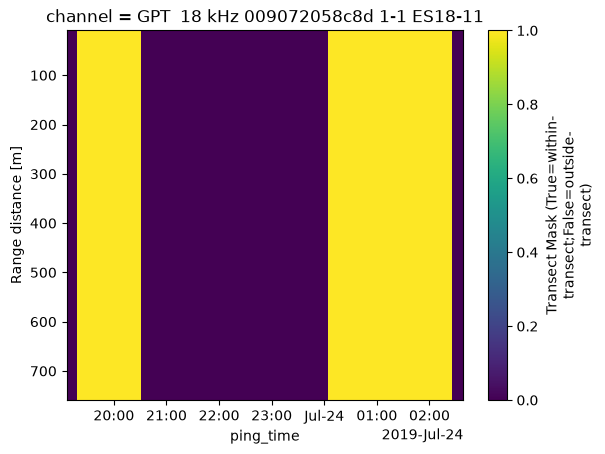

In [25]:
transect_mask.plot(yincrease=False, y="depth")

Find WT segment times:

In [27]:
%%time

# Find time indices where mask is 1
target_indices = np.where(
    transect_mask.isel(depth=0).values == 1
)[0]

# Split into two groups by finding the largest gap
gaps = np.diff(target_indices)
split_idx = np.argmax(gaps) # index where the gap is largest

# Grab WT times
first_WT_times = transect_mask.isel(
    ping_time=target_indices[:split_idx+1]
)["ping_time"].drop_vars("channel")
second_WT_times = transect_mask.isel(
    ping_time=target_indices[split_idx+1:]
)["ping_time"].drop_vars("channel")

CPU times: user 365 ms, sys: 44.8 ms, total: 409 ms
Wall time: 1.11 s


Now we can view the timestamps belonging to the first and second WT segments:

In [28]:
first_WT_times

<xarray.DataArray 'ping_time' (ping_time: 1867)> Size: 15kB
array(['2019-07-23T19:17:53.794107000', '2019-07-23T19:17:56.557264000',
       '2019-07-23T19:17:59.321423000', ..., '2019-07-23T20:31:08.904371000',
       '2019-07-23T20:31:11.665531000', '2019-07-23T20:31:14.424688000'],
      shape=(1867,), dtype='datetime64[ns]')
Coordinates:
  * ping_time  (ping_time) datetime64[ns] 15kB 2019-07-23T19:17:53.794107 ......

In [29]:
second_WT_times

<xarray.DataArray 'ping_time' (ping_time: 4917)> Size: 39kB
array(['2019-07-24T00:04:38.494974000', '2019-07-24T00:04:41.259130000',
       '2019-07-24T00:04:44.022289000', ..., '2019-07-24T02:26:00.803324000',
       '2019-07-24T02:26:02.418417000', '2019-07-24T02:26:04.034510000'],
      shape=(4917,), dtype='datetime64[ns]')
Coordinates:
  * ping_time  (ping_time) datetime64[ns] 39kB 2019-07-24T00:04:38.494974 ......

Note that the recorded times are in Coordinated Universal Time (UTC), while the survey was conducted on the West Coast of the United States during daytime hours in the Pacific Standard Time (PST).

We now split the combined Sv dataset in first and second WT segments:

In [30]:
%%time

# Split WT segments
ds_first_WT_Sv = ds_combined_Sv.sel(ping_time=first_WT_times.values)
ds_second_WT_Sv = ds_combined_Sv.sel(ping_time=second_WT_times.values)

# Save to Zarr stores and offload computation to disk
first_Sv_filename = "ds_first_WT_Sv.zarr"
second_Sv_filename = "ds_second_WT_Sv.zarr"
ds_first_WT_Sv.to_zarr(
    combined_zarr_directory_path / first_Sv_filename,
    mode="w",
    compute=True,
    align_chunks=True,
)
ds_second_WT_Sv.to_zarr(
    combined_zarr_directory_path / second_Sv_filename,
    mode="w",
    compute=True,
    align_chunks=True,
)

# Lazy-load the Zarr stores
ds_first_WT_Sv = xr.open_dataset(
    combined_zarr_directory_path / first_Sv_filename,
    engine="zarr",
    chunks={},
)
ds_second_WT_Sv = xr.open_dataset(
    combined_zarr_directory_path / second_Sv_filename,
    engine="zarr",
    chunks={},
)

CPU times: user 13.1 s, sys: 867 ms, total: 14 s
Wall time: 32.7 s


We can also check longitude extent and average latitude of the WT segments. We expect the latitudes to be close to equal across the transect segments as the transect is oriented east-west:

In [31]:
first_WT_start_lon = float(ds_first_WT_Sv["longitude"].min().values)
first_WT_end_lon = float(ds_first_WT_Sv["longitude"].max().values)
print(
    f"First WT segment longitude range: {first_WT_start_lon:.3f}° to {first_WT_end_lon:.3f}°"
)
first_WT_mean_lat = float(ds_first_WT_Sv["latitude"].mean().values)
print(
    f"First WT segment mean latitude: {first_WT_mean_lat:.3f}°"
)

First WT segment longitude range: -125.287° to -124.979°
First WT segment mean latitude: 43.063°


In [32]:
second_WT_start_lon = float(ds_second_WT_Sv["longitude"].min().values)
second_WT_end_lon = float(ds_second_WT_Sv["longitude"].max().values)
print(
    f"Second WT segment longitude range: {second_WT_start_lon:.3f}° to {second_WT_end_lon:.3f}°."
)
second_WT_mean_lat = float(ds_second_WT_Sv["latitude"].mean().values)
print(
    f"Second WT segment mean latitude: {second_WT_mean_lat:.3f}°"
)

Second WT segment longitude range: -124.980° to -124.483°.
Second WT segment mean latitude: 43.064°


## Clean fish mask creation

Parse the `.evl` file using Echoregions' `read_evl` function. The parsing is based on the `.evl` data description shown on Echoview's website: [Line Attributes](https://support.echoview.com/WebHelp/Using_Echoview/Exporting/Exporting_Data/Exporting_line_data.htm).

In [15]:
line_object = er.read_evl(
    "example_data/single_transect_data_organization/transect_53_year_2019_seafloor.evl"
)

We apply an additional 1m offset to the seafloor delination to include more of the seafloor in the downstream seafloor mask. This ensures that all seafloor pixels are removed when subtracting the seafloor mask from the fish mask.

In [16]:
line_object.data["depth"] = line_object.data["depth"].apply(
    lambda x: x - 1
)

Plot the first WT segment’s midwater fish region annotation (lime color for `region_id=5`) with the 38kHz MVBS data. The seafloor is beyond the echo range so there are no seafloor annotations.

In [35]:
ds_first_WT_Sv["channel"]

<xarray.DataArray 'channel' (channel: 5)> Size: 80B
array(['GPT  18 kHz 009072058c8d 1-1 ES18-11',
       'GPT  38 kHz 009072060fbe 2-1 ES38B',
       'GPT  70 kHz 00907205da30 3-1 ES70-7C',
       'GPT 120 kHz 00907205a6d0 4-1 ES120-7C',
       'GPT 200 kHz 00907205aec4 5-1 ES200-7C'], dtype=StringDType())
Coordinates:
  * channel  (channel) StringDType() 80B 'GPT  18 kHz 009072058c8d 1-1 ES18-1...
Attributes:
    long_name:  Vendor channel ID

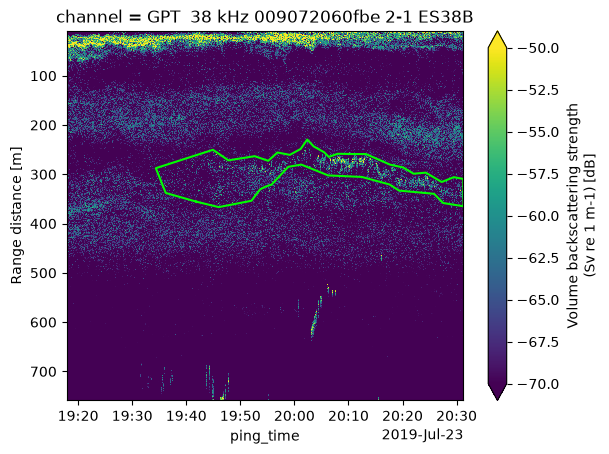

In [36]:
regions_object.plot(region_id=5, close_regions=True, color="lime")
ds_first_WT_Sv["Sv"].sel(
    channel="GPT  38 kHz 009072060fbe 2-1 ES38B"
).plot(
    yincrease=False,
    y="depth",
    vmax=-50,
    vmin=-70,
)

In this notebook, `Range distance` is equivalent to water column depth.

Plot the second WT segment's near-seafloor fish region annotations (lime for `region_id=6`, cyan for `region_id=7`, and white for `region_id=8`) and seafloor annotation (red) with the 38kHz MVBS data:

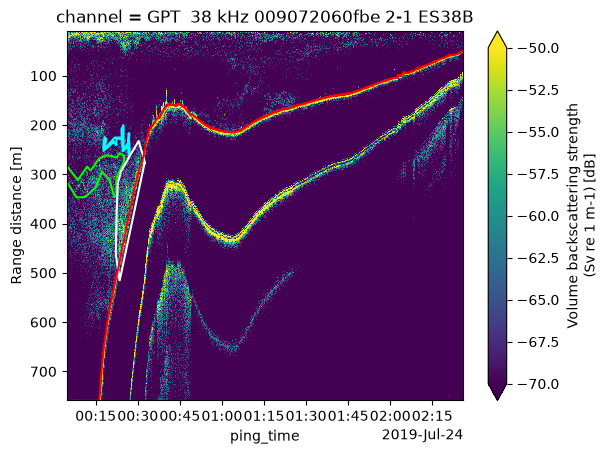

In [38]:
regions_object.plot(
    region_id=6,
    close_regions=True,
    color="lime"
)
regions_object.plot(
    region_id=7,
    close_regions=True,
    color="cyan"
)
regions_object.plot(
    region_id=8,
    close_regions=True,
    color="white"
)
line_object.plot(color="red")
ds_second_WT_Sv["Sv"].sel(
    channel="GPT  38 kHz 009072060fbe 2-1 ES38B"
).plot(
    yincrease=False,
    y="depth",
    vmax=-50,
    vmin=-70,
)

Zoomed-in view of the fish and seafloor intersection:

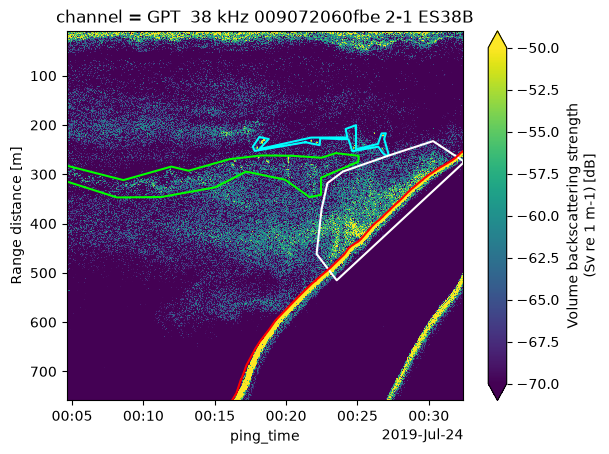

In [21]:
min_time = regions_object.select_region(
    region_id=[6, 7, 8]
)["region_bbox_left"].min()
max_time = regions_object.select_region(
    region_id=[6, 7, 8]
)["region_bbox_right"].max()
regions_object.plot(
    region_id=6,
    close_regions=True,
    color="lime"
)
regions_object.plot(
    region_id=7,
    close_regions=True,
    color="cyan"
)
regions_object.plot(
    region_id=8,
    close_regions=True,
    color="white"
)
line_object.plot(start_time=min_time, end_time=max_time, color="red")
ds_second_WT_Sv["Sv"].sel(
    channel="GPT  38 kHz 009072060fbe 2-1 ES38B"
).sel(ping_time=slice(min_time, max_time)).plot(
    yincrease=False,
    y="depth",
    vmax=-50,
    vmin=-70,
)

The `region_id=8` fish region has seafloor that we will need to remove.

### Create region and seafloor masks

Create first WT segment's fish region mask:

In [43]:
# Mask region
ds_first_WT_fish_regions, _ = regions_object.region_mask(
    ds_first_WT_Sv["Sv"].isel(channel=0).unify_chunks(), region_id=[5]
)

# Save to Zarr and offload computation to disk
ds_first_WT_fish_regions.to_zarr(
    combined_zarr_directory_path / "ds_first_WT_fish_regions.zarr",
    mode="w",
    compute=True,
)

# Lazy-load the Zarr store
ds_first_WT_fish_regions = xr.open_dataset(
    combined_zarr_directory_path / "ds_first_WT_fish_regions.zarr",
    engine="zarr",
    chunks={},
)

Create second WT segment's fish region masks:

In [45]:
# Mask regions
ds_second_WT_fish_regions, _ = regions_object.region_mask(
    ds_second_WT_Sv["Sv"].isel(channel=0).unify_chunks(), region_id=[6, 7, 8]
)

# Save to Zarr and offload computation to disk
ds_second_WT_fish_regions.to_zarr(
    combined_zarr_directory_path / "ds_second_WT_fish_regions.zarr",
    mode="w",
    compute=True,
)

# Lazy-load the Zarr store
ds_second_WT_fish_regions = xr.open_dataset(
    combined_zarr_directory_path / "ds_second_WT_fish_regions.zarr",
    engine="zarr",
    chunks={},
)

Create second WT segment's seafloor mask:

In [47]:
# Mask seafloor
ds_second_WT_seafloor, _ = line_object.seafloor_mask(ds_second_WT_Sv["Sv"].isel(channel=0).unify_chunks())

# Save to Zarr and offload computation to disk
ds_second_WT_seafloor.to_zarr(
    combined_zarr_directory_path / "ds_second_WT_seafloor.zarr",
    mode="w",
    compute=True,
)

# Lazy-load the Zarr store
ds_second_WT_seafloor = xr.open_dataset(
    combined_zarr_directory_path / "ds_second_WT_seafloor.zarr",
    engine="zarr",
    chunks={},
)

### Remove seafloor contamination from fish region masks

Apply seafloor removal to the second WT segment's fish region masks:

In [48]:
# Seafloor removal
da_second_WT_clean_fish_regions = xr.where(
    ds_second_WT_seafloor["mask"] == 0,
    ds_second_WT_fish_regions["mask_3d"],
    0,
)
ds_second_WT_clean_fish_regions = da_second_WT_clean_fish_regions.to_dataset(
    name="mask_3d"
)

# Save to Zarr and offload computation to disk
ds_second_WT_clean_fish_regions.to_zarr(
    combined_zarr_directory_path / "ds_second_WT_clean_fish_regions.zarr",
    mode="w",
    compute=True,
)

# Lazy-load the Zarr store
ds_second_WT_clean_fish_regions = xr.open_dataset(
    combined_zarr_directory_path / "ds_second_WT_clean_fish_regions.zarr",
    engine="zarr",
    chunks={},
)

The `region_id = 8` fish region should be the only region that has changed with this seafloor removal operation:

In [8]:
# Assert equality for `region_id` 6 and 7
assert ds_second_WT_fish_regions["mask_3d"].sel(region_id=6).equals(
    ds_second_WT_clean_fish_regions["mask_3d"].sel(region_id=6)
)

assert ds_second_WT_fish_regions["mask_3d"].sel(region_id=7).equals(
    ds_second_WT_clean_fish_regions["mask_3d"].sel(region_id=7)
)

assert not ds_second_WT_fish_regions["mask_3d"].sel(region_id=8).equals(
    ds_second_WT_clean_fish_regions["mask_3d"].sel(region_id=8)
)

Check that no intersections exist between the clean region masks and the seafloor masks:

In [11]:
number_of_intersections = int(
    xr.where(
        (ds_second_WT_seafloor["mask"] == 1) & \
        (ds_second_WT_clean_fish_regions["mask_3d"].sel(region_id=8) == 1),
        1,
        0,
    ).sum().compute()
)
print(
    "Number of intersections between the clean fish region masks and the seafloor mask:",
    number_of_intersections
)

Number of intersections between the clean fish region masks and the seafloor mask: 0


Plot the clean fish mask regions:

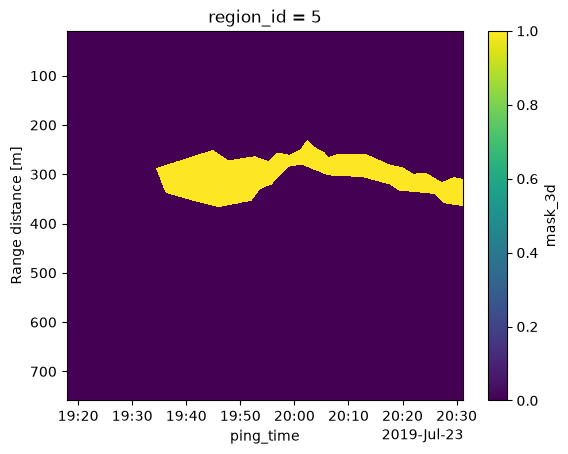

In [52]:
ds_first_WT_fish_regions["mask_3d"].plot(yincrease=False, y="depth")

Yellow (1) indicates fish and purple (0) indicates non-fish.

Note that for the second WT segment, there are 3 fish regions, so we will plot them separately using their unique `region_id`:

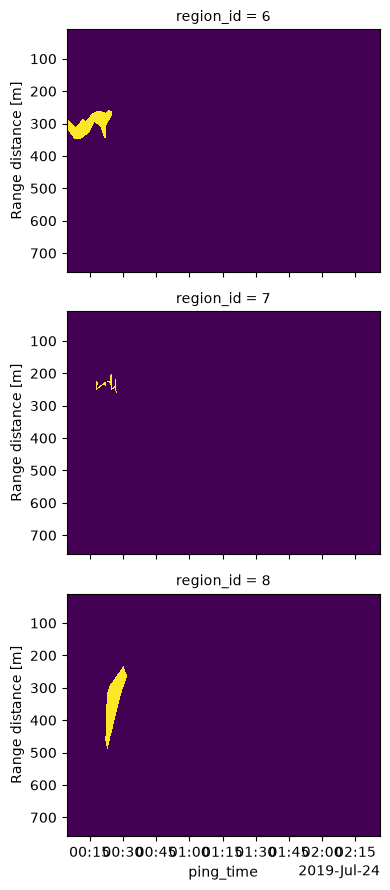

In [53]:
ds_second_WT_clean_fish_regions["mask_3d"].plot(
    yincrease=False,
    y="depth",
    row="region_id",
    # remove colorbar from rhs that encompasses the entire vertical axis
    add_colorbar=False,
)

### Converting instance segmentation masks to semantic segmentation masks

For the second WT segment, the regions are currently separated into 3 masks in the `mask_3d` DataArray. This is the format that is used for instance segmentation, as the algorithm assigns each pixel a predefined class label (e.g., fish) and distinguishes between individual objects of the same class. In contrast, semantic segmentation assigns each pixel a class label without distinguishing between objects of the same class.

We demonstrate how to convert `mask_3d` into a mask fit for semantic segmentation:

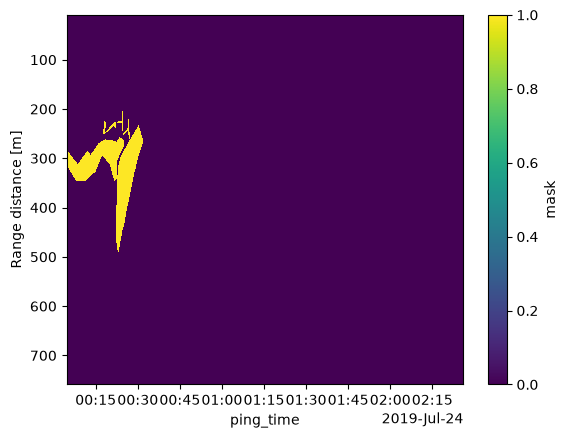

In [54]:
ds_second_WT_clean_fish_regions["mask"] = ds_second_WT_clean_fish_regions["mask_3d"].any(
    dim="region_id"
)
ds_second_WT_clean_fish_regions["mask"].plot(
    yincrease=False, y="depth",
)

### Bounding boxes for object detection

For each region of the second WT segment, we shrink the corresponding region mask such to contain the minimum amount of time-depth coordinates to encompass the non-background portion of the region. We then select the minimum and maximum of these reduced coordinates to define the bounding box vertices for object detection.

In [62]:
vertices = {}
boolean_mask = ds_second_WT_clean_fish_regions[
    "mask_3d"
].astype(bool).compute()
for region_id in boolean_mask["region_id"]:
    boolean_mask_sliced = boolean_mask.sel(
        region_id=region_id
    ).where(
        boolean_mask.sel(region_id=region_id),
        # `drop=True` ensures reduction of the mask coordinates
        drop=True,
    )
    min_depth = boolean_mask_sliced["depth"].min().values.item()
    max_depth = boolean_mask_sliced["depth"].max().values.item()
    min_ping_time = boolean_mask_sliced["ping_time"].min().values
    max_ping_time = boolean_mask_sliced["ping_time"].max().values
    # Add a small offset so that the left side of the bounding box
    # for `region_id=6` is not directly at the first time coordinate
    # of the mask:
    if region_id == 6:
        min_ping_time += np.timedelta64(5, "s")
    vertices[int(region_id)] = {
        "top_left": (min_depth, min_ping_time),
        "top_right": (min_depth, max_ping_time),
        "bottom_left": (max_depth, min_ping_time),
        "bottom_right": (max_depth, max_ping_time),
    }

Plot the bounding boxes defined by the vertices alongside the semantic segmentation mask:

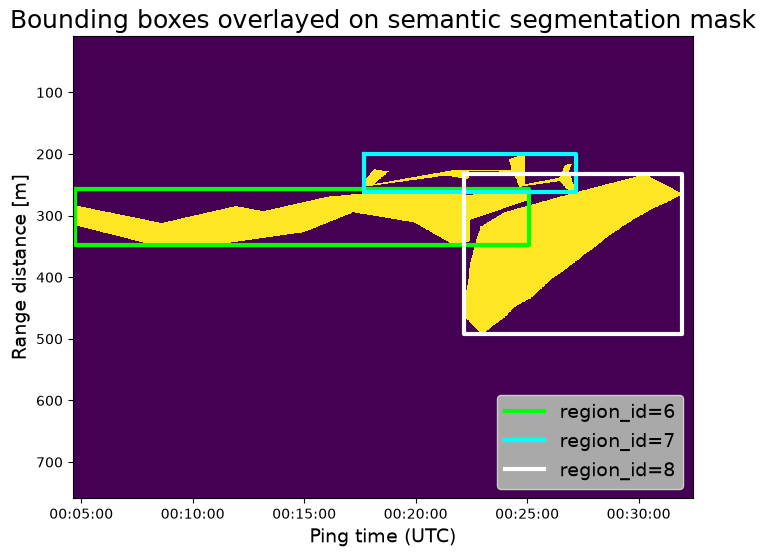

In [63]:
# Define plot size
fig, ax = plt.subplots(figsize=(8, 6))

# Plot mask using image show
mask = ds_second_WT_clean_fish_regions["mask_3d"].sel(
    ping_time=slice(min_time, max_time)
).any(dim="region_id")
depths = mask["depth"].values
ping_times = mask["ping_time"].values
mask_values = mask.values
extent = [
    ping_times.min(),
    ping_times.max(),
    depths.max(),
    depths.min(),
]
im = mask.plot(y="depth", yincrease=False,ax=ax, add_colorbar=False)

# Overlay regions
region_colors = {6: "lime", 7: "cyan", 8: "white"}
for region_id, verts in vertices.items():
    bounding_box = [
        verts["top_left"],
        verts["top_right"],
        verts["bottom_right"],
        verts["bottom_left"],
        verts["top_left"],
    ]
    depths_box, ping_times_box = zip(*bounding_box)
    ax.plot(
        ping_times_box,
        depths_box,
        color=region_colors[region_id],
        linewidth=3,
        label=f"region_id={region_id}"
    )
ax.set_xlabel("Ping time (UTC)", fontsize=14)
ax.set_ylabel("Range distance [m]", fontsize=14)
ax.legend(fontsize=14, facecolor='darkgray', framealpha=1, loc="lower right")
ax.set_title(
    "Bounding boxes overlayed on semantic segmentation mask",
    fontsize=18
)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
plt.show()

## Package versions

In [58]:
from datetime import datetime, timezone

print(f"echopype: {ep.__version__}, xarray: {xr.__version__}")
print(f"\n{datetime.now(timezone.utc)}")

echopype: 0.12.1.dev2+gdff609ee5, xarray: 2026.9.0

2026-10-28 21:51:09.744529+00:00
